# Inverse Problems 2026 - Exercise 1 (home exercises)

___
## Task 1
The following Python code reproduces the results for the inverse heat distribution problem obtained in the first set of lecture notes. Modify it for the following setup.

Use the end time $T = 0.05$. What’s the rank of $A$ now? Add similar noise to the observation with standard deviation $0.001$
as in the slides. How many singular values can be used before reconstruction becomes unstable? Include a plot of your solution in the answer.

Rank of A: 26


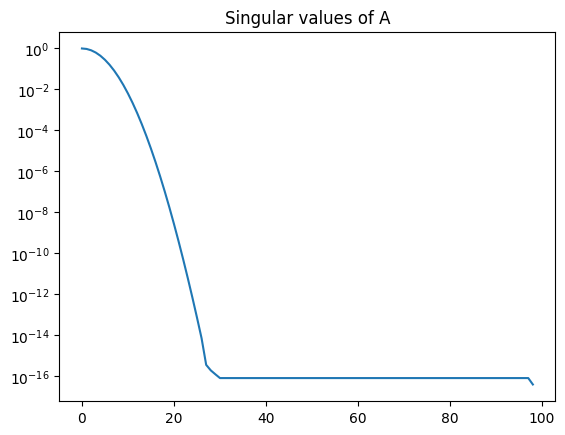

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la

T = 0.05 # 0.1 original
N = 100
h = np.pi/N
B = np.diag(np.ones(N-2), k=-1) - 2*np.eye(N-1) + np.diag(np.ones(N-2), k=1) # Tridiagonal matrix
B[0,0] = -1 # left boundary condition
B[-1,-1] = -1 # right boundary condition
B = B / h**2 # B corresponds to second derivative

A = la.expm(T * B) # Matrix exponential
[U, Svals, Vt] = la.svd(A) # Singular Value Decomposition

plt.semilogy(Svals)
plt.title("Singular values of A");
print(f"Rank of A: {np.linalg.matrix_rank(A)}") # rank 26 when T = 0.05

In [ ]:
sigma = 0.001
sing_val_mask = (Svals >= sigma)
n_sing_vals = np.sum(sing_val_mask)
print(f"Using {n_sing_vals} singular values")

Using 12 singular values


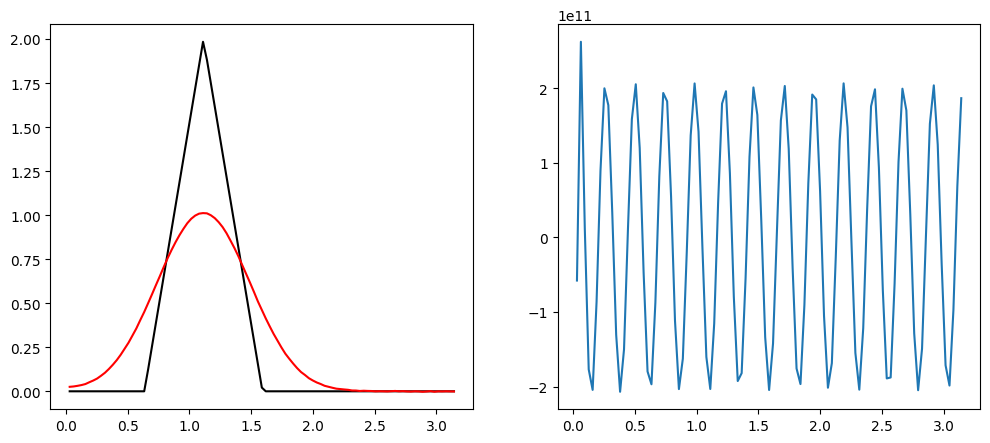

In [ ]:
x = np.linspace(h, np.pi, N-1).T
a, b1, b2 = 40*np.pi/30, -8/3, 20/3
peak = 35
f = np.maximum(np.concatenate([a * x[:peak] + b1, -a* x[peak:] + b2]), 0) # Ground truth solution

w_true = A @ f # Data
w_noisy = w_true + sigma*np.random.normal(0, 1,N-1) # Noisy data
if sigma == 0:
    w = w_true
else:
    w = w_noisy
out = la.lstsq(A, w)
f_stupid = out[0]

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(1,2,1)
ax1.plot(x, f, 'k', x, w, 'r')

ax2 = fig.add_subplot(1,2,2)
ax2.plot(x, f_stupid);

Text(0.5, 1.0, 'Reconstruction with 11 singular values')

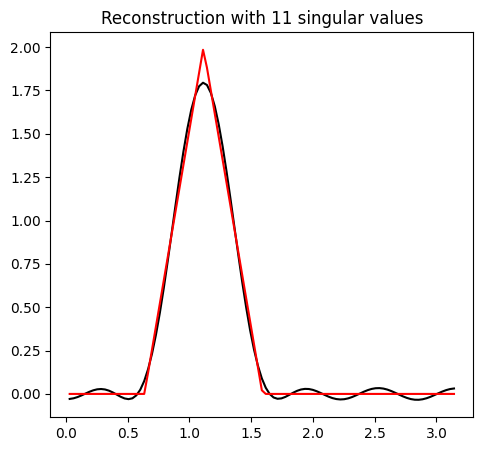

In [ ]:
# truncated svd
k = 11
idx = N-1-k
idx = np.concatenate([1.0/Svals[0:k], np.zeros((N-1)-k)])

inv_Bk = Vt.T @ np.diag(idx) @ U.T
sol = inv_Bk @ w_noisy

fig2 = plt.figure(figsize=(12,5))
ax2 = fig2.add_subplot(1,2,1)
ax2.plot(x, sol, 'k', x, f, 'r')
plt.title(f"Reconstruction with {k} singular values")

___
In the following exercises we learn to solve 1D deconvolution problems. The direct problem is defined as

$$ g(x) = Af(x) = \int k(x −y)f(y)dy, $$

where the domain of integration is a unit interval. As you might remember from Functional Analysis the mapping $A : C[0,1) \to C[0,1)$ is compact and, therefore, the inverse problem is ill-posed.
___

## Task 2
Run the following code cell. Plot the reconstructed vectors `recn1`, `recn2` and `recn3`, then explain how each is obtained. How does an _inverse crime_ affect the reconstructions?

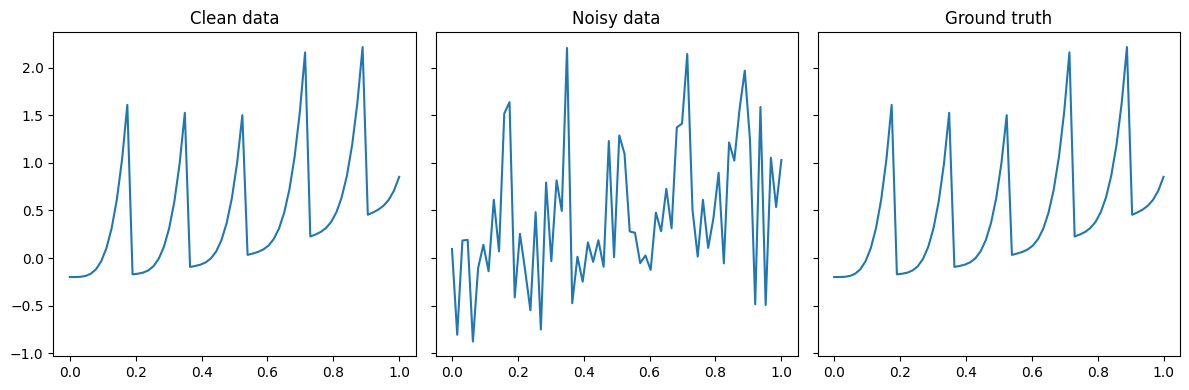

In [ ]:
rng = np.random.default_rng(42)

n = 64
xx = np.linspace(0, 1, n)

def fun(x):
    return 0.05*((4*x)**2 - 4) + 0.05*np.mod(14*x,2.5)**4

psf = np.array([.05, .2, .45, .25, .05]) # Point spread function

A = la.convolution_matrix(psf, n, mode="same")
B = la.inv(A)

data_clean = A @ fun(xx)

sigma = 0.1 # Noise level
data_noisy = data_clean + sigma*rng.standard_normal(n)

recn1 = B @ data_clean # linear construction
recn2 = B @ data_noisy # noisy construction, naive inverse
recn3 = fun(xx)
# plots
fig, axes = plt.subplots(1, 3, sharex=True, sharey=True , figsize=(12,4))
axes[0].plot(xx, recn1)
axes[1].plot(xx, recn2)
axes[2].plot(xx, recn3)
axes[0].set_title("Clean data")
axes[1].set_title("Noisy data")
axes[2].set_title("Ground truth")
fig.tight_layout()
plt.show()

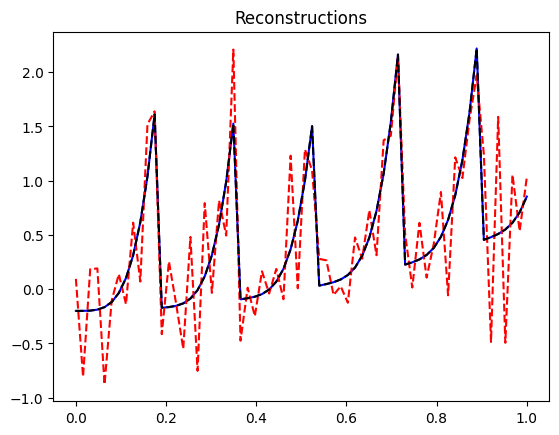

In [ ]:
plt.plot(xx, recn1,'b')
plt.plot(xx, recn2,'r--')
plt.plot(xx, recn3,'k--')
plt.title("Reconstructions")
plt.show()

We have discrete vectors of parameters, xx. fun(xx) generates the ground truth given the values of xx. A is the forward matrix for which we define a point spread function (psf) and a build a convolution matrix that simulates the blurring of the signals by the actual system. The matrix B is created by taking the inverse of A. Then for recn1 and recn2 we apply the the inverse operator to the clean and noisy data. The inverse crime happens when we use the same forward operator matrix A and discretization in order to generate a synthetic test data. Essentially A is used for both blurring and unblurring. In practice, you never have the same exact A. The results appear better than they should be. The crime hides the numerical instabilities, for example by taking the simple invers of A. Also the error are might be not easily visible because the inverse crimes hides the discretization errors. And since you will not have two identical matrices, with real-life data the reconstruction will different. We can avoid it by using a different numerical solver or a finer grid to generate the synthetic data. It should be different from the ones used to build the reconstruction operator B.

___
## Task 3 (Truncated SVD)
Apply truncated SVD with the following code. The routine plots TSVD solution with truncation levels corresponding to saving 5, 10, 20, 40, 60, 80 and 100% of the singular values. Hack this routine and figure what is the optimal truncation level for your unknown assuming you don't know the function `fun`? What criterion would you use? (There are multiple ways of optimizing and no single right answers.)

As default, the routine adds normal random noise to the discrete data with standard deviation $\sigma = 0.1$. Produce data also with $\sigma = 0.02$ and $\sigma = 0.2$. How do these choices affect the 'optimal' truncation level?

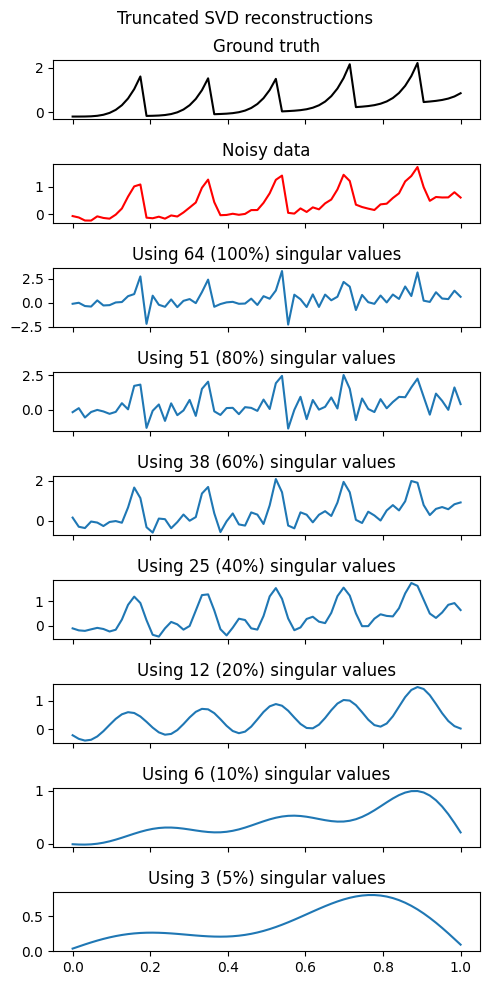

In [ ]:
data_clean = np.convolve(fun(np.linspace(0, 1, 2*n)), psf, mode="same")[::2] # Data simulated at twice the resolution
ground_truth = fun(xx)

sigma = 0.1 # Noise level
data_noisy = data_clean + sigma*rng.standard_normal((n))

[U, Svals, Vt] = la.svd(A) # Singular Value Decomposition

sv_percents = np.array([5, 10, 20, 40, 60, 80, 100])

fig, axs = plt.subplots(len(sv_percents) + 2, sharex=True)
fig.set_size_inches((5, 10))
fig.suptitle("Truncated SVD reconstructions")

axs[0].plot(xx, ground_truth, 'k')
axs[0].set_title("Ground truth")

axs[1].plot(xx, data_noisy, 'r')
axs[1].set_title("Noisy data")

for iii, p in enumerate(sv_percents[::-1]):
    nsv = np.int16(n * p / 100) # Number of singular values used
    Sp_inv = np.zeros(n)
    Sp_inv[:nsv] = 1 / Svals[:nsv]
    Sp_inv = np.diag(Sp_inv)

    recn = Vt.T @ Sp_inv @ U.T @ data_noisy

    axs[iii+2].plot(xx, recn)
    axs[iii+2].set_title(f"Using {nsv} ({p}%) singular values")
fig.tight_layout()

If the ground truth is not known, we could optimize the truncation level using the Morozov's discrepancy principle.

In [ ]:
ks = np.arange(1,64)
resi = np.zeros([100,1])

for i in range(100):
  inv_Sp = np.zeros(64)
  nsv = i
  inv_Sp[:nsv] = 1 / Svals[:nsv]
  inv_Sp = np.diag(inv_Sp)
  xk = Vt.T @ inv_Sp @ U.T @ data_noisy
  diff_xk = A @ xk - data_noisy
  resi[i] = np.linalg.norm(diff_xk)
delta = np.sqrt(len(data_noisy))*sigma
J = np.abs(resi- delta)
index = np.argmin(J)
print(f"Optimal number of singular values according to Morozov's principle: {index+1}")

Optimal number of singular values according to Morozov's principle: 36


___
## Task 4 (Convolution and its adjoint)

Given two (sufficiently well-behaving) functions $f,g: \mathbb{R}^d \to \mathbb{R}$, their convolution is defined as the linear integral operator
$$ f*g(x) := \int_{\mathbb{R}^d} f(y) g(x - y) dy.$$
Show that
1. $f * g = g * f$,
2. $f * (g * h) = (f * g) * h$,
3. $f * (g + h) = f * g + f * h$,
4. $\widehat{f * g} = \widehat{f} \, \widehat{g}$, where $\widehat{f}(\xi) = \int_{\mathbb{R}^d} f(x) e^{-2 \pi i x \cdot \xi} dx$ is the Fourier transform.

For a fixed sequence $g \in \ell^2(\mathbb{Z})$ (sometimes called the _convolution filter_ or _convolution kernel_), consider the operator $G: \ell^2(\mathbb{Z}) \to \ell^2(\mathbb{Z})$ defined as the following _discrete convolution_
$$ G(f) = f * g = \left( \sum_{i = -\infty}^\infty f_i g_{j - i} \right)_{j=-\infty}^\infty. $$
5. Find its adjoint $G^*$ and in particular, what is the filter of $G^*$?


#### 1. $$ f * g = g * f $$


\begin{equation}
  \begin{split}
  f*g(x) &= \int_{\mathbb{R^d}} f(y)g(x-y)dy \\
  g*f(x) &= \int_{\mathbb{R^d}} g(y)f(x-y)dy \\
  \end{split} \\
\end{equation}
Let's use a substition variable $z$ so that $z = x - y$.Then let's express $y$ and $dy$ in terms of $z$.
\begin{equation}
  \\
  \begin{split}
  y &= x - z\\
  dy &= -dz
  \end{split}
\end{equation}
So then once we substitute
\begin{equation}
  \begin{split}
  f*g(x) &= \int_{\mathbb{R^d}} f(x-z)g(z)(-dz) \\
  &= \int_{\mathbb{R^d}} f(x-z)g(z)(dz)
  \end{split}\\
\end{equation}
Multiplication is commutative so we can rearrange the terms
\begin{equation}
  \begin{split}
  f*g(x) &= \int_{\mathbb{R^d}} g(z)f(x-z)(-dz)
  \end{split}\\
\end{equation}

2. $f * (g * h) = (f * g) * h$

Inside the brackets we have
\begin{equation}
  \begin{split}
  g*h(x) &= \int_{\mathbb{R^d}} g(y)h(x-y)dy \\
  f*g(x) &= \int_{\mathbb{R^d}} f(y)g(x-y)dy \\
  \end{split} \\
\end{equation}
Lets denote the equations above as $u = g*h $ and $v = f*g$.
And denote y in terms of z: $ y = x -z$ and $dy = -dz$.
\begin{equation}
  \begin{split}
  [f*u](x) &= \int_{\mathbb{R^d}} f(y)u(x-z)dz \\
  \end{split} \\
\end{equation}
Then expand $u(x)$ expression
\begin{equation}
  \begin{split}
  u(x-z) &= \int_{\mathbb{R^d}} g(y)h((x-z)-y)dy \\
  \end{split} \\
\end{equation}
Substite this back to $[f*u](x)$
\begin{equation}
  \begin{split}
  [f*u](x) &= \int_{\mathbb{R^d}} f(z)\left(\int_{\mathbb{R^d}} g(y) h(x-z-y)dy\right)dz \\
  \end{split} \\
\end{equation}
According Fubini's theorem, we can arrange the order of the integration
\begin{equation}
  \begin{split}
  [f*u](x) &= \int_{\mathbb{R^d}} \int_{\mathbb{R^d}} f(z) g(y) h(x-z-y)dydz \\
  \end{split} \\
\end{equation}
Let's use change of variables. Let $w = z + y$, $z = w - y$, $dz = dw$.
\begin{equation}
  \begin{split}
  [f*u](x) &= \int_{\mathbb{R^d}} \int_{\mathbb{R^d}} f(w-y) g(y) h(x-w)dwdy \\
  &= \int_{\mathbb{R^d}} \left( \int_{\mathbb{R^d}} f(w-y) g(y) dy\right)h(x-w)dw
  \end{split} \\
\end{equation}
The inner integration is equal to the function $v(w) = (f*g)(w)$.
Substituting back $g*h = u$ and $f*g = v$.
\begin{equation}
  \begin{split}
  [f*u](x) &= (v*h)(x) \\
  f*(g*h) &= (f*g)*h
  \end{split} \\
\end{equation}

3. $f * (g + h) = f * g + f * h$

On the right hand side we have the summation of these two terms
\begin{equation}
  \begin{split}
  f*g(x) &= \int_{\mathbb{R^d}} f(y)g(x-y)dy \\
  f*h(x) &= \int_{\mathbb{R^d}} f(y)h(x-y)dy \\
  \end{split} \\
\end{equation}
The sum gives us
\begin{equation}
  \begin{split}
  \int_{\mathbb{R^d}} f(y)g(x-y)dy  + \int_{\mathbb{R^d}} f(y)h(x-y)dy &= \int_{\mathbb{R^d}} f(y)[g(x-y) + h(x-y)]dy \\
  &= [f*(g+h)](x)
  \end{split} \\
\end{equation}

4. $\widehat{f * g} = \widehat{f} \, \widehat{g}$, where $\widehat{f}(\xi) = \int_{\mathbb{R}^d} f(x) e^{-2 \pi i x \cdot \xi} dx$ is the Fourier transform.

For a fixed sequence $g \in \ell^2(\mathbb{Z})$ (sometimes called the _convolution filter_ or _convolution kernel_), consider the operator $G: \ell^2(\mathbb{Z}) \to \ell^2(\mathbb{Z})$ defined as the following _discrete convolution_
$$ G(f) = f * g = \left( \sum_{i = -\infty}^\infty f_i g_{j - i} \right)_{j=-\infty}^\infty. $$

\begin{equation}
  \begin{split}
  \widehat{G} &=  \widehat{f*g}(\xi)\\
  &= \int_{\mathbb{R}^d} \left(\int_{\mathbb{R}^d} f(y) g(x-y) dy \right)e^{-2\pi i x \xi}dx
  \end{split}
\end{equation}
We can then change the order of integration according to Fubini's theorem.
\begin{equation}
  \begin{split}
  \widehat{f*g}(\xi)
  &= \int_{\mathbb{R}^d} f(y)\left(\int_{\mathbb{R}^d}  g(x-y)e^{-2\pi i x \xi}dx \right)dy
  \end{split}
\end{equation}
Let's use a change of variable $z = x-y$. It follows that $x = z+y$ and $dy = dz$.
The inner integral becomes
\begin{equation}
  \begin{split}
  \int_{\mathbb{R}^d}  g(x-y)e^{-2\pi i x \xi}dx
  &= \int_{\mathbb{R}^d}  g(z)e^{-2\pi i z \xi} e^{-2\pi i y \xi}dz \\
  &= e^{-2\pi i y \xi}\int_{\mathbb{R}^d}  g(z)e^{-2\pi i z \xi} dz \\
  &= e^{-2\pi i y \xi} ̂\hat{g}(\xi)
  \end{split}
\end{equation}
Then let's substitute this result to the outer integral over $dy$.
\begin{equation}
  \begin{split}
  \widehat{f*g}(\xi)
  &= \int_{\mathbb{R}^d} f(y) \left(e^{-2\pi i y \xi} ̂\hat{g}(\xi) \right)dy \\
  &= \left( \int_{\mathbb{R}^d} f(y)(e^{-2\pi i y \xi} dy \right)\hat{g}(\xi) \\
  &= \hat{f}(\xi)\hat{g}(\xi)
  \end{split}
\end{equation}